# Co-occurrence networks
One distinct comment–islander pair is counted once. Each comment mentioning k islanders contributes k(k−1)/2 undirected pairs. Edge weight is the number of distinct shared comments. This maps shared discussion, not confirmed relationships or alliances.

Use heavy-text `islander_windows` for consistency with 04. Retain its study-period and entrance filters. Report overall and by episode instead of the archive's weekly grouping. Include mentioned islanders with no edges. Compute metrics on all edges; show the strongest quartile only in the simplified visual. Betweenness uses inverse weight as distance. Louvain communities describe this graph and are not objective social groups; episode community IDs are local, not tracked identities.


In [22]:
from pathlib import Path
from itertools import combinations
import duckdb
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
db_path = project_root / "data/love_island_reddit.duckdb"
assert db_path.is_file()
fig_dir = project_root / "viz/network"
export_dir = project_root / "tables/network_dashboard"
fig_dir.mkdir(parents=True, exist_ok=True)
export_dir.mkdir(parents=True, exist_ok=True)

with duckdb.connect(str(db_path)) as con:
    comment_islanders = con.execute("""
        SELECT DISTINCT comment_id, episode, target_islander
        FROM islander_windows
        WHERE keep_analysis = 'Y' AND episode IS NOT NULL
          AND episode >= entrance_episode
        ORDER BY episode, comment_id, target_islander
    """).df()
assert comment_islanders.notna().all().all()
assert comment_islanders.groupby("comment_id").episode.nunique().le(1).all()
print(f"{comment_islanders.comment_id.nunique():,} comments; {comment_islanders.target_islander.nunique()} islanders")


131,709 comments; 34 islanders


## Comment pairs and edge tables

In [23]:
comment_mentions = comment_islanders.groupby(["episode", "comment_id"])["target_islander"].agg(list)
rows = [(episode, cid, a, b)
        for (episode, cid), names in comment_mentions.items()
        for a, b in combinations(sorted(set(names)), 2)]
comment_pairs = pd.DataFrame(rows, columns=["episode", "comment_id", "source", "target"])
assert not comment_pairs.duplicated(["comment_id", "source", "target"]).any()
assert comment_pairs.source.lt(comment_pairs.target).all()
assert len(comment_pairs) == sum(len(v)*(len(v)-1)//2 for v in comment_mentions)

overall_network_edges = (comment_pairs.groupby(["source", "target"]).size()
    .reset_index(name="weight").sort_values("weight", ascending=False))
episode_network_edges = (comment_pairs.groupby(["episode", "source", "target"]).size()
    .reset_index(name="weight").sort_values(["episode", "weight"], ascending=[True, False]))
overall_network_edges["pair_share"] = overall_network_edges.weight / overall_network_edges.weight.sum()
episode_network_edges["pair_share"] = episode_network_edges.weight / episode_network_edges.groupby("episode").weight.transform("sum")
assert overall_network_edges.weight.sum() == episode_network_edges.weight.sum() == len(comment_pairs)
overall_network_edges.head(15)


,source,target,weight,pair_share
377,Melanie Moreno,Sincere Rhea,10616,0.065725
66,Aniya Harvey,Kuman Chandler,6427,0.039790
337,Kayda Bosse,Zacharias Georgiou,6277,0.038862
124,Bryce Alakai Dettloff,Trinity Tatum,5737,0.035519
125,Bryce Alakai Dettloff,Zacharias Georgiou,3449,0.021353
214,Corbin Mims,Mackenzie Annis,3228,0.019985
54,Aniya Harvey,Carl Lee Schmidt,2934,0.018165
361,Mackenzie Annis,Melanie Moreno,2876,0.017806
69,Aniya Harvey,Melanie Moreno,2694,0.016679
350,Kuman Chandler,Sincere Rhea,2483,0.015373


## Centrality and communities
Degree counts distinct neighbors; weighted degree counts shared-comment connections (one comment may contribute several). Weighted eigenvector centrality is calculated separately in each connected component, with L2 normalization within that component, so compare it within components. Isolates receive zero. Component IDs and sizes are retained to make that scope explicit.


In [24]:
def build_network(mentions, edges):
    graph = nx.Graph()
    graph.add_nodes_from(sorted(mentions.target_islander.unique()))
    for edge in edges.itertuples(index=False):
        graph.add_edge(edge.source, edge.target, weight=int(edge.weight), distance=1 / edge.weight)
    return graph

def node_metrics(graph, mentions):
    degree = nx.degree_centrality(graph) if len(graph)>1 else {v: 0.0 for v in graph}
    between = nx.betweenness_centrality(graph, weight="distance", normalized=True)
    eigen, component_id, component_size = {}, {}, {}
    components = sorted(nx.connected_components(graph), key=lambda x: (-len(x), sorted(x)))
    for idx, members in enumerate(components, 1):
        sub = graph.subgraph(members)
        if len(members)==1:
            values = {v: 0.0 for v in members}
        else:
            matrix = nx.to_numpy_array(sub, nodelist=sorted(members), weight="weight")
            _, vectors = np.linalg.eigh(matrix)
            values = dict(zip(sorted(members), np.abs(vectors[:, -1])))
        eigen.update(values)
        component_id.update({v: idx for v in members})
        component_size.update({v: len(members) for v in members})
    groups = (nx.community.louvain_communities(graph, weight="weight", seed=42)
              if graph.number_of_edges() else [{v} for v in graph])
    groups = sorted(groups, key=lambda x: (-len(x), sorted(x)))
    community = {v: idx for idx, group in enumerate(groups, 1) for v in group}
    counts = mentions.groupby("target_islander").comment_id.nunique()
    result = pd.DataFrame({"target_islander": list(graph.nodes)})
    result["num_comments"] = result.target_islander.map(counts)
    for col, lookup in {
        "degree_centrality": degree, "weighted_degree": dict(graph.degree(weight="weight")),
        "betweenness_centrality": between, "eigenvector_centrality": eigen,
        "component_id": component_id, "component_size": component_size, "community": community,
    }.items(): result[col] = result.target_islander.map(lookup)
    result["top_connections"] = result.target_islander.map(lambda v: "; ".join(
        f"{other} ({data['weight']})" for other, data in
        sorted(graph[v].items(), key=lambda item: (-item[1]['weight'], item[0]))[:3]))
    assert result.weighted_degree.sum() == 2 * sum(d["weight"] for _,_,d in graph.edges(data=True))
    return result

G = build_network(comment_islanders, overall_network_edges)
overall_network_nodes = node_metrics(G, comment_islanders)
frames = []
for episode, mentions in comment_islanders.groupby("episode"):
    edges = episode_network_edges.loc[episode_network_edges.episode.eq(episode)]
    metrics = node_metrics(build_network(mentions, edges), mentions)
    metrics.insert(0, "episode", episode)
    frames.append(metrics)
episode_network_nodes = pd.concat(frames, ignore_index=True)
for metric in ["weighted_degree", "betweenness_centrality", "eigenvector_centrality"]:
    episode_network_nodes[f"{metric}_vs_episode"] = (
        episode_network_nodes[metric] - episode_network_nodes.groupby("episode")[metric].transform("mean"))
overall_network_nodes.sort_values("weighted_degree", ascending=False).head(15)


,target_islander,num_comments,degree_centrality,weighted_degree,betweenness_centrality,eigenvector_centrality,component_id,component_size,community,top_connections
21,Melanie Moreno,23557,0.909091,31861,0.282197,0.428899,1,34,4,Sincere Rhea (10616); Mackenzie Annis (2876); ...
27,Sincere Rhea,23188,0.878788,31363,0.149621,0.425137,1,34,4,Melanie Moreno (10616); Kuman Chandler (2483);...
18,Kuman Chandler,18034,0.909091,26083,0.204545,0.310505,1,34,2,Aniya Harvey (6427); Sincere Rhea (2483); Tier...
33,Zacharias Georgiou,17350,0.818182,25010,0.210227,0.300946,1,34,3,Kayda Bosse (6277); Bryce Alakai Dettloff (344...
20,Mackenzie Annis,20217,0.909091,24847,0.556818,0.260211,1,34,1,Corbin Mims (3228); Melanie Moreno (2876); Sin...
2,Aniya Harvey,16788,0.969697,24789,0.140152,0.306964,1,34,2,Kuman Chandler (6427); Carl Lee Schmidt (2934)...
16,Kayda Bosse,12913,0.848485,21580,0.060606,0.275226,1,34,3,Zacharias Georgiou (6277); Melanie Moreno (222...
32,Trinity Tatum,11946,0.939394,19255,0.064394,0.232001,1,34,3,Bryce Alakai Dettloff (5737); Zacharias Georgi...
4,Bryce Alakai Dettloff,13656,0.878788,19236,0.051136,0.235299,1,34,3,Trinity Tatum (5737); Zacharias Georgiou (3449...
9,Corbin Mims,10266,0.878788,16080,0.060606,0.184681,1,34,1,Mackenzie Annis (3228); Parmida Keshani (2184)...


## Symmetric adjacency matrix and fixed layout

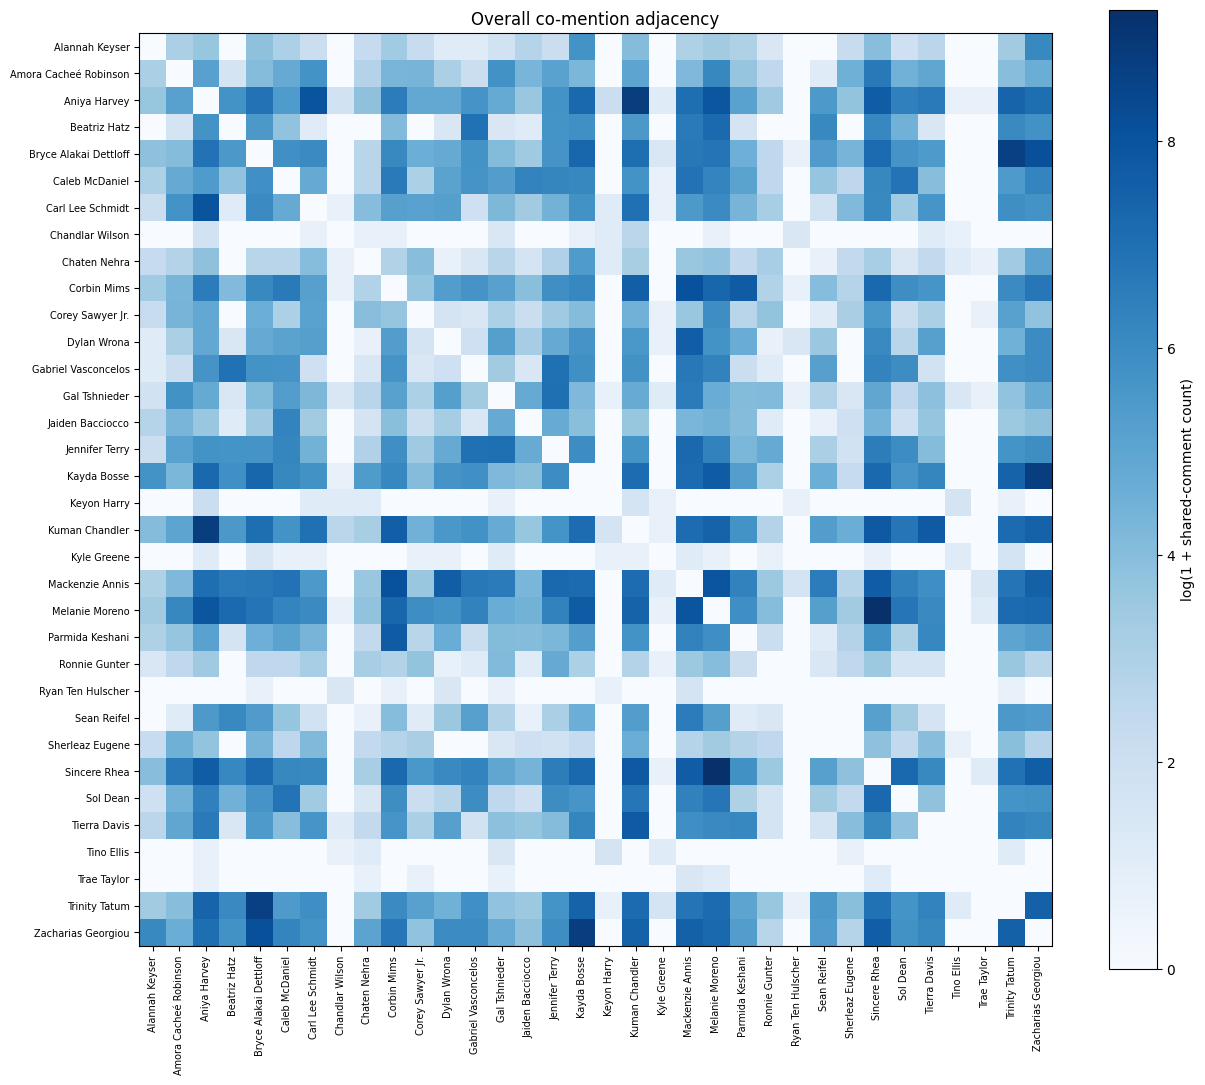

In [25]:
names = sorted(G.nodes)
adjacency = nx.to_pandas_adjacency(G, nodelist=names, weight="weight", dtype=int)
assert np.array_equal(adjacency.values, adjacency.values.T)
assert np.diag(adjacency).sum() == 0
pos = nx.spring_layout(G, weight="weight", seed=42, iterations=200)
network_layout = pd.DataFrame([{"target_islander": v, "x": float(xy[0]), "y": float(xy[1])} for v,xy in pos.items()])
overall_network_nodes = overall_network_nodes.merge(network_layout, on="target_islander", validate="one_to_one")
episode_network_nodes = episode_network_nodes.merge(network_layout, on="target_islander", validate="many_to_one")
fig, ax = plt.subplots(figsize=(13, 11))
image = ax.imshow(np.log1p(adjacency.values), cmap="Blues")
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
ax.set_yticks(range(len(names)), names, fontsize=7)
fig.colorbar(image, ax=ax, label="log(1 + shared-comment count)")
ax.set_title("Overall co-mention adjacency")
fig.tight_layout()
fig.savefig(fig_dir / "adjacency.png", dpi=160)
plt.show()


## Overall network — strongest quartile of edges
All nodes remain visible; graph metrics use the full graph. Colors are overall Louvain communities.

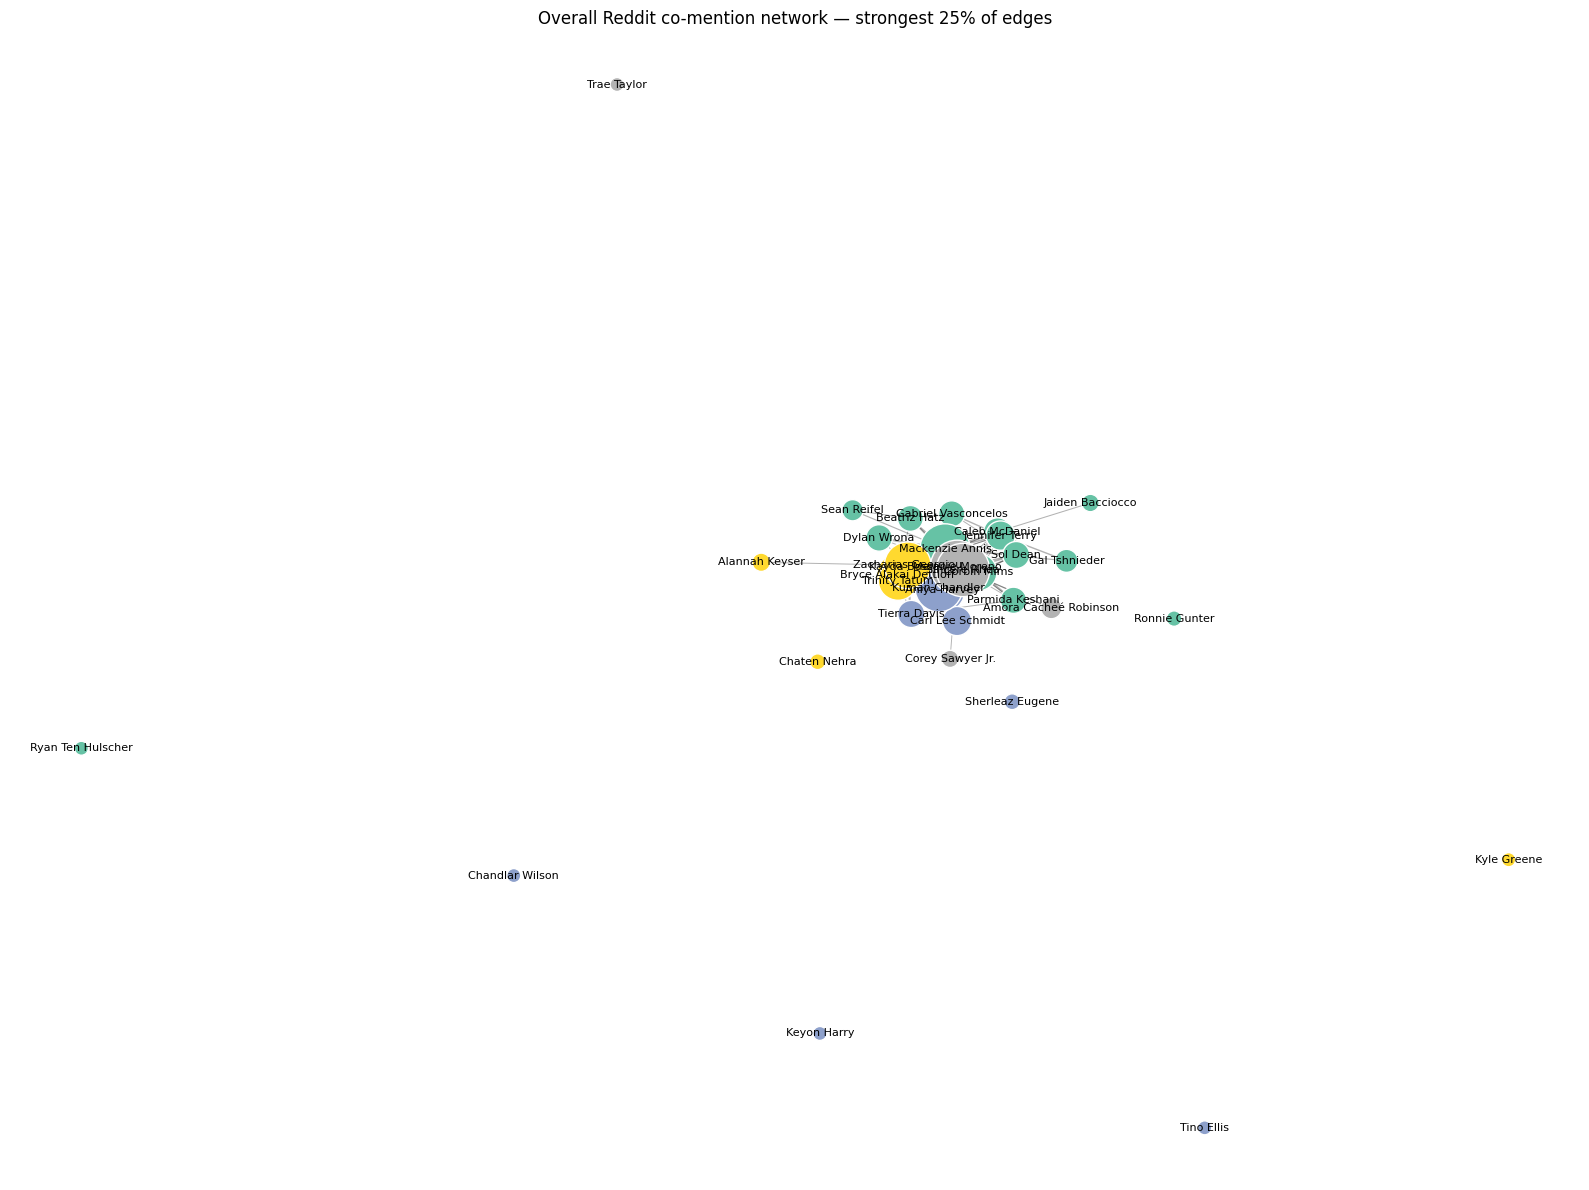

In [26]:
threshold = overall_network_edges.weight.quantile(0.75)
strong_edges = [(a,b) for a,b,d in G.edges(data=True) if d["weight"] >= threshold]
lookup = overall_network_nodes.set_index("target_islander")
fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_edges(G, pos, edgelist=strong_edges, ax=ax, alpha=0.3,
    width=[0.5 + 5*G[a][b]["weight"]/overall_network_edges.weight.max() for a,b in strong_edges])
nx.draw_networkx_nodes(G, pos, ax=ax,
    node_size=[100+1400*lookup.loc[v,"num_comments"]/lookup.num_comments.max() for v in G],
    node_color=[lookup.loc[v,"community"] for v in G], cmap=plt.cm.Set2,
    edgecolors="white")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
ax.set_title("Overall Reddit co-mention network — strongest 25% of edges")
ax.axis("off")
fig.tight_layout()
fig.savefig(fig_dir / "overall_network_strong.png", dpi=180)
plt.show()


## Node information: emojis, sentiment, toxicity
Standout emojis come from the saved overall and episode tables in 04 (lift ≥ 2; minimum 10 occurrences overall or 5 per episode). Top emojis are ranked separately by occurrence count. Both sets are shown; missing emoji summaries display NA. Sentiment uses the saved RoBERTa relative z-score and also shows its raw mean. Toxicity uses the raw 0–1 mean, compared with the unweighted average of islander means in the same view. Comparison baselines include all scored islanders, even if the display hides final exits. Network and sentiment comment counts may differ because their window extraction differs.

In [27]:
# Match hover data to each view; never substitute overall values for missing episode data.
with duckdb.connect(str(db_path)) as con:
    overall_sentiment = con.execute("SELECT * FROM dashboard.overall_relative_metrics").df()
    episode_sentiment = con.execute("SELECT * FROM dashboard.episode_relative_metrics").df()
    overall_emojis = con.execute("SELECT * FROM dashboard.standout_emoji_table").df()
    episode_emojis = con.execute("SELECT * FROM dashboard.episode_emoji_table").df()

with duckdb.connect(str(db_path)) as con:
    overall_emoji_counts = con.execute("SELECT * FROM dashboard.overall_emoji_metrics").df()
    episode_emoji_counts = con.execute("SELECT * FROM dashboard.episode_emoji_metrics").df()

def top_emoji_summary(metrics, keys):
    ranked = metrics.sort_values(keys + ["count", "emoji"], ascending=[True]*len(keys)+[False, True])
    return (ranked.groupby(keys).head(3).groupby(keys, as_index=False)
            .agg(top_emojis=("emoji", " ".join)))

# These tables already contain the selected standout emojis from 04.
overall_emojis = overall_emojis.rename(columns={"Islander": "target_islander", "Standout emojis": "standout_emojis"})
episode_emojis = episode_emojis.rename(columns={"Episode": "episode", "Islander": "target_islander", "Standout emojis": "standout_emojis"})

def enrich_nodes(nodes, sentiment, emojis, emoji_counts, keys):
    metrics = sentiment[keys + ["roberta_mean", "roberta_relative_sentiment", "toxicity_mean", "num_comments"]].copy()
    metrics = metrics.rename(columns={"num_comments": "sentiment_num_comments"})
    if "episode" in keys:
        metrics["toxicity_cast_mean"] = metrics.groupby("episode").toxicity_mean.transform("mean")
    else:
        metrics["toxicity_cast_mean"] = metrics.toxicity_mean.mean()
    def comparison(value):
        if pd.isna(value): return "Unavailable"
        if abs(value) <= 1e-8: return "At Average"
        return "Above Average" if value > 0 else "Below Average"
    metrics["sentiment_comparison"] = metrics.roberta_relative_sentiment.map(comparison)
    metrics["toxicity_comparison"] = (metrics.toxicity_mean - metrics.toxicity_cast_mean).map(comparison)
    extra = [c for c in metrics if c not in keys] + ["top_emojis", "standout_emojis"]
    result = nodes.drop(columns=extra, errors="ignore").merge(metrics,on=keys,how="left",validate="one_to_one")
    result = result.merge(emojis[keys + ["standout_emojis"]],on=keys,how="left",validate="one_to_one")
    result = result.merge(top_emoji_summary(emoji_counts, keys), on=keys, how="left", validate="one_to_one")
    result["top_emojis"] = result.top_emojis.fillna("NA")
    result["standout_emojis"] = result.standout_emojis.fillna("NA")
    return result

overall_network_nodes = enrich_nodes(overall_network_nodes, overall_sentiment, overall_emojis, overall_emoji_counts, ["target_islander"])
episode_network_nodes = enrich_nodes(episode_network_nodes, episode_sentiment, episode_emojis, episode_emoji_counts, ["episode", "target_islander"])

# LLM assessment of audience approval, matched to the exact network view.
with duckdb.connect(str(db_path)) as con:
    overall_approval = con.execute("SELECT target_islander, approval, has_approval_assessment FROM dashboard.overall_community_approval").df()
    episode_approval = con.execute("SELECT target_islander, episode, approval, has_approval_assessment FROM dashboard.episode_community_approval").df()

def add_approval(nodes, assessments, keys):
    result = nodes.drop(columns=["approval", "has_approval_assessment", "audience_approval"], errors="ignore").merge(
        assessments, on=keys, how="left", validate="one_to_one"
    )
    result["audience_approval"] = result.approval.map({1: "Yes", 0: "No"}).fillna("Unclear")
    result.loc[result.has_approval_assessment.isna(), "audience_approval"] = "No assessment"
    return result

overall_network_nodes = add_approval(overall_network_nodes, overall_approval, ["target_islander"])
episode_network_nodes = add_approval(episode_network_nodes, episode_approval, ["episode", "target_islander"])


## Interactive overall / episode network
Fixed positions across episodes. Node size reflects distinct comment counts; colors retain overall community membership for visual consistency. Episode community assignments remain available in exported tables. Edge hover shows shared-comment counts. The display filter does not affect saved metrics.
Episode views hide islanders after their final `exit_episode` and before entrance, and hide their incident edges. The exit episode is included. Temporary absences are ignored. Overall views and saved full-discussion metrics retain all mentions; node hover metrics refer to that full network.


In [61]:
import pandas as pd
import numpy as np
import duckdb
import plotly.graph_objects as go
import plotly.colors
from html import escape

# 1. Fetch sentiment and emoji data
with duckdb.connect(str(db_path)) as con:
    overall_sentiment = con.execute("SELECT * FROM dashboard.overall_relative_metrics").df()
    episode_sentiment = con.execute("SELECT * FROM dashboard.episode_relative_metrics").df()
    overall_emojis = con.execute("SELECT * FROM dashboard.standout_emoji_table").df()
    episode_emojis = con.execute("SELECT * FROM dashboard.episode_emoji_table").df()
    overall_emoji_counts = con.execute("SELECT * FROM dashboard.overall_emoji_metrics").df()
    episode_emoji_counts = con.execute("SELECT * FROM dashboard.episode_emoji_metrics").df()

def top_emoji_summary(metrics, keys):
    ranked = metrics.sort_values(keys + ["count", "emoji"], ascending=[True]*len(keys)+[False, True])
    return (ranked.groupby(keys).head(3).groupby(keys, as_index=False)
            .agg(top_emojis=("emoji", " ".join)))

overall_emojis = overall_emojis.rename(columns={"Islander": "target_islander", "Standout emojis": "standout_emojis"})
episode_emojis = episode_emojis.rename(columns={"Episode": "episode", "Islander": "target_islander", "Standout emojis": "standout_emojis"})

def enrich_nodes(nodes, sentiment, emojis, emoji_counts, keys):
    metrics = sentiment[keys + ["roberta_mean", "roberta_relative_sentiment", "toxicity_mean", "num_comments"]].copy()
    metrics = metrics.rename(columns={"num_comments": "sentiment_num_comments"})
    if "episode" in keys:
        metrics["toxicity_cast_mean"] = metrics.groupby("episode").toxicity_mean.transform("mean")
    else:
        metrics["toxicity_cast_mean"] = metrics.toxicity_mean.mean()
    def comparison(value):
        if pd.isna(value): return "Unavailable"
        if abs(value) <= 1e-8: return "At Average"
        return "Above Average" if value > 0 else "Below Average"
    metrics["sentiment_comparison"] = metrics.roberta_relative_sentiment.map(comparison)
    metrics["toxicity_comparison"] = (metrics.toxicity_mean - metrics.toxicity_cast_mean).map(comparison)
    extra = [c for c in metrics if c not in keys] + ["top_emojis", "standout_emojis"]
    result = nodes.drop(columns=extra, errors="ignore").merge(metrics,on=keys,how="left",validate="one_to_one")
    result = result.merge(emojis[keys + ["standout_emojis"]],on=keys,how="left",validate="one_to_one")
    result = result.merge(top_emoji_summary(emoji_counts, keys), on=keys, how="left", validate="one_to_one")
    result["top_emojis"] = result.top_emojis.fillna("NA")
    result["standout_emojis"] = result.standout_emojis.fillna("NA")
    return result

overall_network_nodes = enrich_nodes(overall_network_nodes, overall_sentiment, overall_emojis, overall_emoji_counts, ["target_islander"])
episode_network_nodes = enrich_nodes(episode_network_nodes, episode_sentiment, episode_emojis, episode_emoji_counts, ["episode", "target_islander"])

# 2. Fetch and add LLM Assessment data
with duckdb.connect(str(db_path)) as con:
    overall_approval = con.execute("SELECT target_islander, approval, has_approval_assessment FROM dashboard.overall_community_approval").df()
    episode_approval = con.execute("SELECT target_islander, episode, approval, has_approval_assessment FROM dashboard.episode_community_approval").df()

def add_approval(nodes, assessments, keys):
    result = nodes.drop(columns=["approval", "has_approval_assessment", "audience_approval"], errors="ignore").merge(
        assessments, on=keys, how="left", validate="one_to_one"
    )
    result["audience_approval"] = result.approval.map({1: "Yes", 0: "No"}).fillna("Unclear")
    result.loc[result.has_approval_assessment.isna(), "audience_approval"] = "No assessment"
    return result

overall_network_nodes = add_approval(overall_network_nodes, overall_approval, ["target_islander"])
episode_network_nodes = add_approval(episode_network_nodes, episode_approval, ["episode", "target_islander"])

# 3. Fetch and add Kalshi data
with duckdb.connect(str(db_path)) as con:
    kalshi_overall = con.execute("SELECT target_islander, kalshi_price FROM dashboard.kalshi_overall_prices").df()
    kalshi_episode = con.execute("SELECT target_islander, episode, kalshi_price FROM dashboard.kalshi_episode_prices").df()

def add_kalshi(nodes, kalshi_data, keys):
    return nodes.drop(columns=["kalshi_price"], errors="ignore").merge(
        kalshi_data, on=keys, how="left", validate="many_to_one"
    )

overall_network_nodes = add_kalshi(overall_network_nodes, kalshi_overall, ["target_islander"])
episode_network_nodes = add_kalshi(episode_network_nodes, kalshi_episode, ["episode", "target_islander"])

# 4. Set up Plotly Network Visualization
DISPLAY_EDGE_QUANTILE = 0.75
palette = plotly.colors.qualitative.Set2
community_lookup = overall_network_nodes.set_index("target_islander").community.to_dict()
max_comments = overall_network_nodes.num_comments.max()

def node_hover(row):
    def number(value, fmt=".3f"):
        return "Unavailable" if pd.isna(value) else format(value, fmt)
    sentiment_label = "Unavailable" if pd.isna(row.sentiment_comparison) else row.sentiment_comparison.replace("At Average", "Average")
    toxicity_label = "Unavailable" if pd.isna(row.toxicity_comparison) else row.toxicity_comparison.replace("At Average", "Average")
    kalshi_label = "Unavailable" if pd.isna(getattr(row, "kalshi_price", np.nan)) else f"{row.kalshi_price:.1f}¢"
    
    return (
        f"<b>{escape(row.target_islander)}</b><br>"
        f"Comments (network): {row.num_comments:,}<br>"
        f"Comments (sentiment): {number(row.sentiment_num_comments, ',.0f')}<br><br>"
        f"<b>Kalshi Prediction:</b> {kalshi_label}<br><br>"
        f"<b>Top emojis:</b> {escape(row.top_emojis)}<br>"
        f"<b>Standout emojis:</b> {escape(row.standout_emojis)}<br><br>"
        f"<b>Audience Approval (LLM):</b> {escape(row.audience_approval)}<br>"
        f"<b>Sentiment:</b> {sentiment_label} ({number(row.roberta_relative_sentiment, '+.2f')} z)<br>"
        f"<b>Toxicity:</b> {toxicity_label} ({number(row.toxicity_mean)})<br><br>"
        f"Full-discussion weighted degree: {row.weighted_degree}<br>"
        f"Full-discussion top connections: {escape(row.top_connections)}"
    )

def network_traces(nodes, edges):
    shown = edges.loc[edges.weight.ge(edges.weight.quantile(DISPLAY_EDGE_QUANTILE))] if len(edges) else edges
    xs, ys, mx, my, hover = [], [], [], [], []
    for e in shown.itertuples(index=False):
        x0,y0 = pos[e.source]; x1,y1 = pos[e.target]
        xs.extend([x0,x1,None]); ys.extend([y0,y1,None])
        mx.append((x0+x1)/2); my.append((y0+y1)/2)
        hover.append(f"{e.source} ↔ {e.target}<br>Shared comments: {e.weight}")
    return [
        go.Scatter(x=xs,y=ys,mode="lines",line=dict(color="rgba(100,100,100,0.3)",width=1.5),hoverinfo="skip"),
        go.Scatter(x=mx,y=my,mode="markers",marker=dict(size=15,color="rgba(0,0,0,0)"),hovertext=hover,hoverinfo="text"),
        go.Scatter(x=nodes.x,y=nodes.y,mode="markers+text",text=nodes.target_islander,textposition="top center",
            marker=dict(size=10+45*np.sqrt(nodes.num_comments/max_comments),
                        color=[palette[(community_lookup[v]-1)%len(palette)] for v in nodes.target_islander],line=dict(color="white",width=1)),
            hovertext=[node_hover(r) for r in nodes.itertuples(index=False)],
            hoverinfo="text")]

# 5. Build frames and render
cast_lifecycle = pd.read_csv(project_root / "data/metadata/islander_metadata.csv")
assert cast_lifecycle.islander.is_unique
assert cast_lifecycle[["entrance_episode", "exit_episode"]].notna().all().all()
assert cast_lifecycle.exit_episode.ge(cast_lifecycle.entrance_episode).all()
assert set(overall_network_nodes.target_islander).issubset(set(cast_lifecycle.islander))

views = [("Overall", overall_network_nodes, overall_network_edges)]
for ep in sorted(comment_islanders.episode.unique()):
    # Keep the exit episode itself; remove only later episodes.
    active = set(cast_lifecycle.loc[
        cast_lifecycle.entrance_episode.le(ep) & cast_lifecycle.exit_episode.ge(ep),
        "islander",
    ])
    nodes = episode_network_nodes.loc[
        episode_network_nodes.episode.eq(ep)
        & episode_network_nodes.target_islander.isin(active)
    ].copy()
    edges = episode_network_edges.loc[
        episode_network_edges.episode.eq(ep)
        & episode_network_edges.source.isin(nodes.target_islander)
        & episode_network_edges.target.isin(nodes.target_islander)
    ].copy()
    assert set(edges.source).union(edges.target).issubset(set(nodes.target_islander))
    views.append((f"Episode {ep}", nodes, edges))

# Helper function to dynamically calculate axis bounds with padding
def get_padded_range(coords, padding=0.2):
    if len(coords) == 0:
        return [-1, 1]
    c_min, c_max = coords.min(), coords.max()
    c_range = c_max - c_min
    if c_range == 0:
        c_range = 1
    return [c_min - (c_range * padding), c_max + (c_range * padding)]

# Build frames with dynamic axis ranges applied to the Layout of each frame
frames = []
for label, nodes, edges in views:
    x_bounds = get_padded_range(nodes.x)
    y_bounds = get_padded_range(nodes.y)
    
    frame = go.Frame(
        name=label, 
        data=network_traces(nodes, edges),
        layout=go.Layout(
            title=f"Reddit co-mentions — {label}",
            xaxis=dict(range=x_bounds),
            yaxis=dict(range=y_bounds)
        )
    )
    frames.append(frame)

fig = go.Figure(data=network_traces(views[0][1], views[0][2]), frames=frames)

# Apply the dynamic bounds of the first view (Overall) to the base layout
base_x = get_padded_range(views[0][1].x)
base_y = get_padded_range(views[0][1].y)

fig.update_layout(
    title="Reddit co-mentions — Overall",
    showlegend=False,
    height=850,
    xaxis=dict(visible=False, range=base_x),
    yaxis=dict(visible=False, range=base_y),
    plot_bgcolor="white",
    margin=dict(t=80, b=100, l=30, r=30),
    sliders=[dict(
        currentvalue=dict(prefix="View: "),
        steps=[
            dict(
                label=label,
                method="animate",
                args=[
                    [label],
                    dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))
                ]
            ) for label, _, _ in views
        ]
    )]
)

fig.write_html(fig_dir / "co_mention_network.html", include_plotlyjs=True)
fig.show()

In [62]:
# Apply the dynamic bounds of the first view (Overall) to the base layout
base_x = get_padded_range(views[0][1].x)
base_y = get_padded_range(views[0][1].y)

fig.update_layout(
    title="Reddit co-mentions — Overall",
    showlegend=False,
    height=850,
    xaxis=dict(visible=False, range=base_x),
    yaxis=dict(visible=False, range=base_y),
    plot_bgcolor="white",
    margin=dict(t=80, b=100, l=30, r=30),
    # 1. Add the Play and Pause buttons
    updatemenus=[dict(
        type="buttons",
        showactive=False,
        y=-0.05,            # Position below the graph
        x=0.05,             # Position slightly from the left
        xanchor="right",
        yanchor="top",
        buttons=[
            dict(
                label="Play ▶",
                method="animate",
                args=[None, dict(frame=dict(duration=800, redraw=True), 
                                 transition=dict(duration=300),
                                 fromcurrent=True,
                                 mode="immediate")]
            ),
            dict(
                label="Pause ⏸",
                method="animate",
                args=[[None], dict(frame=dict(duration=0, redraw=False), 
                                   transition=dict(duration=0),
                                   mode="immediate")]
            )
        ]
    )],
    # 2. Update the slider to shift it slightly to the right, making room for the buttons
    sliders=[dict(
        currentvalue=dict(prefix="View: "),
        x=0.1,              # Shift slider right to make room for buttons
        y=-0.05,
        len=0.9,            # Slightly shorten the slider so it fits
        xanchor="left",
        yanchor="top",
        steps=[
            dict(
                label=label,
                method="animate",
                args=[
                    [label],
                    dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))
                ]
            ) for label, _, _ in views
        ]
    )]
)

fig.write_html(fig_dir / "co_mention_network.html", include_plotlyjs=True)
fig.show()

## Plot

In [37]:
episode_network_nodes.columns

Index(['episode', 'target_islander', 'num_comments', 'degree_centrality',
       'weighted_degree', 'betweenness_centrality', 'eigenvector_centrality',
       'component_id', 'component_size', 'community', 'top_connections',
       'weighted_degree_vs_episode', 'betweenness_centrality_vs_episode',
       'eigenvector_centrality_vs_episode', 'x', 'y', 'roberta_mean',
       'roberta_relative_sentiment', 'toxicity_mean', 'sentiment_num_comments',
       'toxicity_cast_mean', 'sentiment_comparison', 'toxicity_comparison',
       'standout_emojis', 'top_emojis', 'approval', 'has_approval_assessment',
       'audience_approval', 'kalshi_price'],
      dtype='object')

,episode,target_islander,num_comments,degree_centrality,weighted_degree,betweenness_centrality,eigenvector_centrality,component_id,component_size,community,...,toxicity_comparison,standout_emojis,top_emojis,approval,has_approval_assessment,audience_approval,kalshi_price,islander,entrance_episode,exit_episode
0,1,Aniya Harvey,224,1.00,393,0.000000,0.280227,1,10,1,...,Below Average,NA,😭 👀 🥹,1,True,Yes,21.45,Aniya Harvey,1,35
1,1,Beatriz Hatz,400,1.00,429,0.166667,0.289784,1,10,2,...,Above Average,🥰 🔥,😭 😂 🔥,1,True,Yes,29.01,Beatriz Hatz,1,10
2,1,Bryce Alakai Dettloff,408,1.00,378,0.000000,0.261522,1,10,3,...,Below Average,NA,😭 😂 💀,0,True,No,42.86,Bryce Alakai Dettloff,1,35
3,1,Kuman Chandler,451,1.00,403,0.000000,0.281881,1,10,1,...,Above Average,NA,😭 😂 😩,1,True,Yes,29.11,Kuman Chandler,1,30
4,1,Mackenzie Annis,682,1.00,551,0.277778,0.386468,1,10,4,...,Above Average,💀 😂,😭 😂 💀,0,True,No,14.53,Mackenzie Annis,1,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
673,35,Trinity Tatum,507,0.68,654,0.000000,0.306779,1,24,4,...,Above Average,🥹 🥰,😭 🥹 😂,1,True,Yes,91.55,Trinity Tatum,1,35
654,35,Bryce Alakai Dettloff,605,0.68,718,0.053333,0.332873,1,24,4,...,Above Average,🤍 🥰 🥹,😭 🥹 😂,1,True,Yes,91.22,Bryce Alakai Dettloff,1,35
652,35,Aniya Harvey,645,0.68,809,0.256667,0.372178,1,24,3,...,Above Average,🩷 🥺 👀,😭 💀 🥹,1,True,Yes,7.97,Aniya Harvey,1,35
656,35,Carl Lee Schmidt,622,0.68,736,0.070000,0.351116,1,24,3,...,Above Average,🩷 🥺,😭 🥹 😂,1,True,Yes,7.06,Carl Lee Schmidt,20,35


In [58]:
import pandas as pd
import numpy as np
import plotly.express as px

# 1. Load data and ensure standard integer types
cast_lifecycle = pd.read_csv(project_root / "data/metadata/islander_metadata.csv")
nodes_df = episode_network_nodes.copy()
nodes_df["episode"] = nodes_df["episode"].astype(float).astype(int)

all_episodes = sorted(nodes_df["episode"].unique())
all_islanders = cast_lifecycle["islander"].unique()

# 2. Build a full grid: EVERY Islander exists in EVERY Episode
idx = pd.MultiIndex.from_product([all_episodes, all_islanders], names=["episode", "target_islander"])
plot_df = pd.DataFrame(index=idx).reset_index()

# 3. Merge entrance/exit bounds to determine when they are actually in the villa
plot_df = plot_df.merge(
    cast_lifecycle[["islander", "entrance_episode", "exit_episode"]],
    left_on="target_islander",
    right_on="islander",
    how="left"
)
# Create a True/False mask for when they are on screen
plot_df["is_active"] = (plot_df["episode"] >= plot_df["entrance_episode"]) & (plot_df["episode"] <= plot_df["exit_episode"])

# 4. Merge the actual Reddit and Kalshi metrics
plot_df = plot_df.merge(
    nodes_df[["episode", "target_islander", "roberta_relative_sentiment", "kalshi_price", "sentiment_num_comments"]],
    on=["episode", "target_islander"],
    how="left"
)

# 5. Forward-fill metrics chronologically per Islander
plot_df = plot_df.sort_values(["target_islander", "episode"])
plot_df["roberta_relative_sentiment"] = plot_df.groupby("target_islander")["roberta_relative_sentiment"].ffill()
plot_df["kalshi_price"] = plot_df.groupby("target_islander")["kalshi_price"].ffill()

# 6. Apply Active Masking (The Magic Fix)
# If active but missing comments, set size to 1. If inactive, set size to 0.
plot_df["sentiment_num_comments"] = np.where(
    plot_df["is_active"],
    plot_df["sentiment_num_comments"].fillna(1).clip(lower=1),
    0
)

# If active but metric is still NaN (e.g. Day 1 of Casa Amor), fill with 0.
plot_df.loc[plot_df["is_active"], "roberta_relative_sentiment"] = plot_df.loc[plot_df["is_active"], "roberta_relative_sentiment"].fillna(0.0)
plot_df.loc[plot_df["is_active"], "kalshi_price"] = plot_df.loc[plot_df["is_active"], "kalshi_price"].fillna(0.0)

# If INACTIVE, force coordinates to NaN so Plotly renders them invisibly!
plot_df.loc[~plot_df["is_active"], ["roberta_relative_sentiment", "kalshi_price"]] = np.nan

# 7. Calculate Terciles (only on active rows)
plot_df["sentiment_category"] = plot_df.groupby("episode")["roberta_relative_sentiment"].transform(
    lambda s: pd.qcut(s.dropna(), q=3, labels=["Below Average", "Average", "Above Average"], duplicates="drop") if s.notna().any() else np.nan
)

# 8. Apply Dodging (only on active rows)
cat_map = {"Below Average": 0, "Average": 1, "Above Average": 2}
plot_df["x_base"] = plot_df["sentiment_category"].map(cat_map).astype(float)
plot_df["price_rounded"] = plot_df["kalshi_price"].round(0)

active_mask = plot_df["is_active"]
plot_df["dodge_rank"] = plot_df[active_mask].groupby(["episode", "sentiment_category", "price_rounded"]).cumcount()
plot_df["dodge_count"] = plot_df[active_mask].groupby(["episode", "sentiment_category", "price_rounded"])["target_islander"].transform("count")

offset_step = 0.15
plot_df["x_dodged"] = np.nan
plot_df.loc[active_mask, "x_dodged"] = plot_df.loc[active_mask, "x_base"] + (plot_df.loc[active_mask, "dodge_rank"] - (plot_df.loc[active_mask, "dodge_count"] - 1) / 2.0) * offset_step

# Sort chronologically one last time for the animation engine
plot_df = plot_df.sort_values(["episode", "target_islander"])

# 9. Build the Plotly Graph
fig_scatter = px.scatter(
    plot_df,
    x="x_dodged",
    y="kalshi_price",
    animation_frame="episode",
    animation_group="target_islander",
    size="sentiment_num_comments",
    color="target_islander",
    hover_name="target_islander",
    text="target_islander",
    title="Reddit Sentiment vs. Kalshi Win Probability Over Time",
    labels={
        "kalshi_price": "Kalshi Price (Win Probability %)",
        "episode": "Episode",
    },
    range_x=[-0.5, 2.5],
    range_y=[-5, 105],
    height=700,
    category_orders={"target_islander": sorted(all_islanders)},
)

fig_scatter.update_xaxes(
    tickvals=[0, 1, 2],
    ticktext=["Below Average", "Average", "Above Average"],
    title_text="Reddit Sentiment",
)
fig_scatter.update_traces(textposition="top center")
fig_scatter.update_layout(showlegend=False)

fig_scatter.write_html(fig_dir / "sentiment_vs_kalshi.html", include_plotlyjs=True)
fig_scatter.show()

/var/folders/kz/_f6tp6zx7cs2j282q7zq2sfw0000gp/T/ipykernel_75179/3637786634.py:65: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df["dodge_rank"] = plot_df[active_mask].groupby(["episode", "sentiment_category", "price_rounded"]).cumcount()
/var/folders/kz/_f6tp6zx7cs2j282q7zq2sfw0000gp/T/ipykernel_75179/3637786634.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df["dodge_count"] = plot_df[active_mask].groupby(["episode", "sentiment_category", "price_rounded"])["target_islander"].transform("count")


In [63]:
# 10. Add colored background zones for the terciles
fig_scatter.add_vrect(
    x0=-0.5, x1=0.5,
    fillcolor="pink", 
    opacity=0.2,
    layer="below", 
    line_width=0
)

fig_scatter.add_vrect(
    x0=0.5, x1=1.5,
    fillcolor="lightyellow", 
    opacity=0.3,
    layer="below", 
    line_width=0
)

fig_scatter.add_vrect(
    x0=1.5, x1=2.5,
    fillcolor="lightgreen", 
    opacity=0.2,
    layer="below", 
    line_width=0
)

# Render
fig_scatter.write_html(fig_dir / "sentiment_vs_kalshi.html", include_plotlyjs=True)
fig_scatter.show()

In [55]:
episode_network_nodes.to_csv("episode_network_nodes.csv", index=False)

In [ ]:
import statsmodels.formula.api as smf

# Drop rows missing the metrics we want to test
regression_df = episode_network_nodes.dropna(
    subset=["kalshi_price", "roberta_relative_sentiment", "toxicity_mean", "sentiment_num_comments"]
).copy()

# Run a multiple linear regression
# Formula: Price is a function of Sentiment + Toxicity + Volume of Comments
model = smf.ols(
    formula="kalshi_price ~ roberta_relative_sentiment + toxicity_mean + sentiment_num_comments", 
    data=regression_df
)
results = model.fit()

# Print the statistical summary
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           kalshi_price   R-squared:                       0.085
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     20.79
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           6.89e-13
Time:                        17:56:38   Log-Likelihood:                -2885.7
No. Observations:                 675   AIC:                             5779.
Df Residuals:                     671   BIC:                             5797.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [35]:
import statsmodels.formula.api as smf

model = smf.ols(
    formula="kalshi_price ~ roberta_relative_sentiment + toxicity_mean + sentiment_num_comments + C(episode)", 
    data=regression_df
)
results = model.fit()

with open("regression_summary.txt", "w") as f:
    f.write(results.summary().as_text())

# Extract the results table into a pandas dataframe
results_df = pd.DataFrame({
    "Coefficient": results.params,
    "P-Value": results.pvalues
})

# Filter to only show the metrics we actually care about
core_metrics = ["Intercept", "roberta_relative_sentiment", "toxicity_mean", "sentiment_num_comments"]
print(results_df.loc[core_metrics])

                            Coefficient       P-Value
Intercept                     21.825520  1.010224e-04
roberta_relative_sentiment     5.534868  3.984074e-13
toxicity_mean                 16.607687  7.801563e-02
sentiment_num_comments         0.008479  4.989802e-05


After controlling for **episode** (categorical):

1. `roberta_relative_sentiment` is insanely significant ($p = 3.98 \times 10^{-13}$). A 1-unit increase in positive sentiment is now worth +5.53¢.
2. More discussion means higher Kalshi odds. `sentiment_num_comments` is highly significant ($p = 4.98 \times 10^{-5}$).
3. The "Hate-Watch" confirmation: `toxicity_mean` sits at a p-value of 0.078. Because it is still above the standard 0.05 threshold of statistical significance, we can quietly conclude that the prediction market does not consistently price in Reddit's vitriol.

## Save network data to DuckDB and CSV

In [31]:
network_tables = {
    "overall_network_edges": overall_network_edges,
    "episode_network_edges": episode_network_edges,
    "overall_network_nodes": overall_network_nodes,
    "episode_network_nodes": episode_network_nodes,
    "network_layout": network_layout,
}
assert not overall_network_nodes.target_islander.duplicated().any()
assert not episode_network_nodes.duplicated(["episode","target_islander"]).any()
with duckdb.connect(str(db_path)) as con:
    con.execute("CREATE SCHEMA IF NOT EXISTS dashboard")
    con.execute("BEGIN TRANSACTION")
    try:
        for name, table in network_tables.items():
            con.register("network_export",table)
            con.execute(f"CREATE OR REPLACE TABLE dashboard.{name} AS SELECT * FROM network_export")
            assert con.execute(f"SELECT COUNT(*) FROM dashboard.{name}").fetchone()[0] == len(table)
            con.unregister("network_export")
        con.execute("COMMIT")
    except Exception:
        con.execute("ROLLBACK")
        raise
for name,table in network_tables.items():
    table.to_csv(export_dir / f"{name}.csv", index=False)
adjacency.rename_axis("target_islander").to_csv(export_dir / "overall_network_adjacency.csv")
print("Saved network tables to DuckDB and CSV; interactive chart and PNGs are in",fig_dir)


Saved network tables to DuckDB and CSV; interactive chart and PNGs are in /Users/edieespejo/GitHub/data-by-edie/004-love-island/viz/network
